# Aadhithya S
# 3122245002001
# It-A

# DLA - LSTM on Time Series Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import get_file
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Input
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# Data Loading

67921/67921 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (3650, 1)
         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8


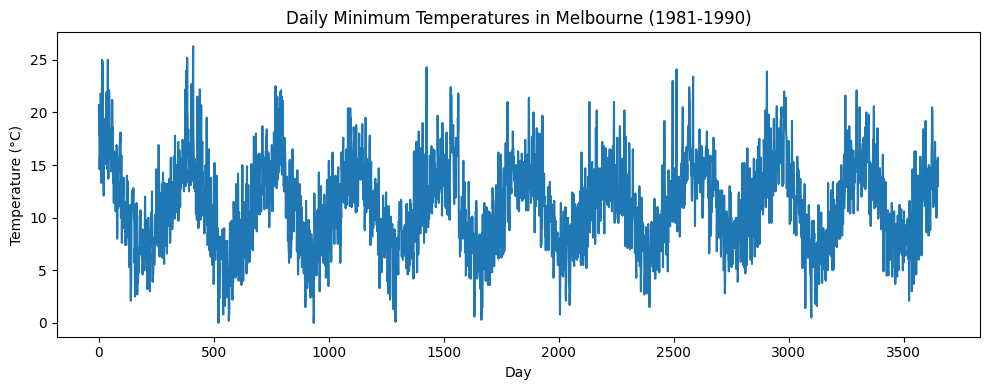

In [2]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
csv_path = get_file("daily-min-temperatures.csv", origin=DATA_URL)
df = pd.read_csv(csv_path)
series = df.iloc[:, 1].values.astype("float32").reshape(-1, 1)

print("Dataset shape:", series.shape)
print(df.head())

plt.figure(figsize=(10, 4))
plt.plot(series)
plt.title("Daily Minimum Temperatures in Melbourne (1981-1990)")
plt.xlabel("Day")
plt.ylabel("Temperature (°C)")
plt.tight_layout()
plt.show()

# Preprocessing & Sliding Window Sequences

In [3]:
# Scale data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(series)

LOOK_BACK = 30  # Use previous 30 days of temperatures to predict the next day

def create_dataset(data, look_back=1):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back, 0])
        y.append(data[i + look_back, 0])
    return np.array(X), np.array(y)

X, y = create_dataset(scaled, LOOK_BACK)

# Chronological split (no shuffling)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Reshape to [samples, timesteps, features] for Keras layers
X_train = X_train.reshape((X_train.shape[0], LOOK_BACK, 1))
X_test = X_test.reshape((X_test.shape[0], LOOK_BACK, 1))

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (2896, 30, 1) | Test shape: (724, 30, 1)


# Helper Function for Training & Evaluation

In [4]:
def train_and_evaluate(model, name, epochs=50):
    model.compile(optimizer="adam", loss="mse")
    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=epochs, batch_size=32, verbose=0
    )

    train_pred = model.predict(X_train, verbose=0)
    test_pred = model.predict(X_test, verbose=0)

    # Invert scaling back to original temperature units (°C)
    train_pred_inv = scaler.inverse_transform(train_pred)
    y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
    test_pred_inv = scaler.inverse_transform(test_pred)
    y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

    train_rmse = np.sqrt(mean_squared_error(y_train_inv, train_pred_inv))
    test_rmse = np.sqrt(mean_squared_error(y_test_inv, test_pred_inv))
    print(f"[{name}] Train RMSE: {train_rmse:.2f} °C | Test RMSE: {test_rmse:.2f} °C")

    plt.figure(figsize=(6, 4))
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(f"{name} - Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return test_pred_inv, y_test_inv, test_rmse

# Model Architectures & Training

[SimpleRNN] Train RMSE: 2.46 °C | Test RMSE: 2.23 °C


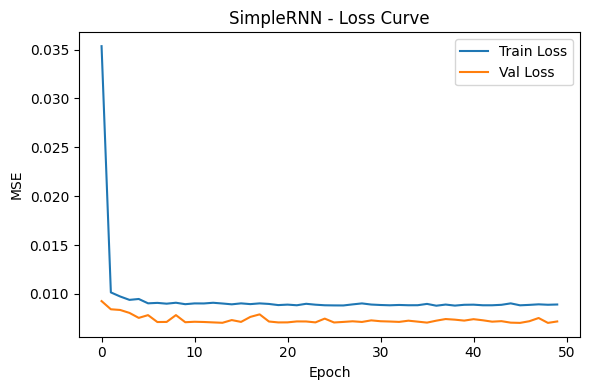

[LSTM] Train RMSE: 2.44 °C | Test RMSE: 2.20 °C


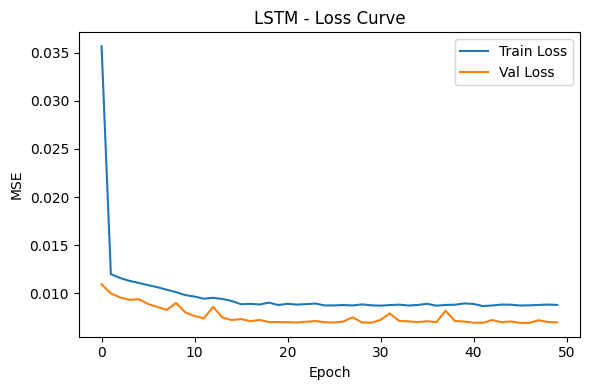

[GRU] Train RMSE: 2.47 °C | Test RMSE: 2.24 °C


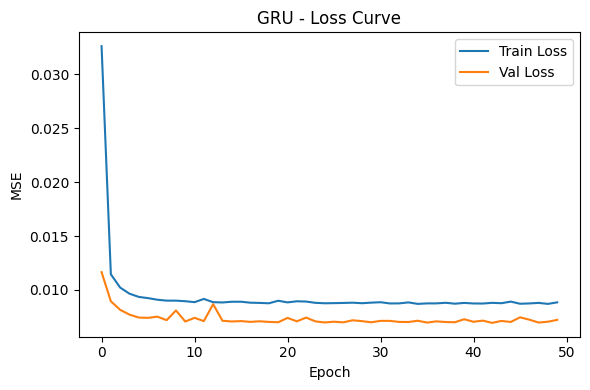

In [5]:
# Model A: SimpleRNN
rnn_model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    SimpleRNN(50, activation="tanh"),
    Dense(1)
])
rnn_pred, y_test_inv, rnn_rmse = train_and_evaluate(rnn_model, "SimpleRNN")

# Model B: LSTM
lstm_model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    LSTM(50, activation="tanh"),
    Dense(1)
])
lstm_pred, _, lstm_rmse = train_and_evaluate(lstm_model, "LSTM")

# Model C: GRU
gru_model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    GRU(50, activation="tanh"),
    Dense(1)
])
gru_pred, _, gru_rmse = train_and_evaluate(gru_model, "GRU")

# Visualization & Final Comparison

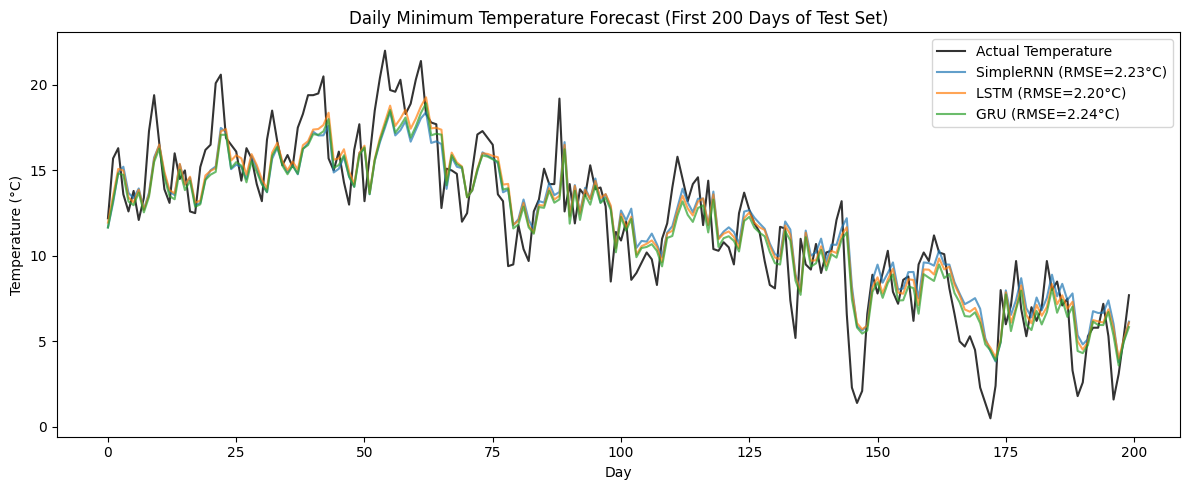

Final Summary -> SimpleRNN: 2.23 °C | LSTM: 2.20 °C | GRU: 2.24 °C


In [6]:
plt.figure(figsize=(12, 5))
plt.plot(y_test_inv[:200], label="Actual Temperature", color='black', alpha=0.8, linewidth=1.5)
plt.plot(rnn_pred[:200], label=f"SimpleRNN (RMSE={rnn_rmse:.2f}°C)", alpha=0.7)
plt.plot(lstm_pred[:200], label=f"LSTM (RMSE={lstm_rmse:.2f}°C)", alpha=0.7)
plt.plot(gru_pred[:200], label=f"GRU (RMSE={gru_rmse:.2f}°C)", alpha=0.7)
plt.title("Daily Minimum Temperature Forecast (First 200 Days of Test Set)")
plt.xlabel("Day")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Final Summary -> SimpleRNN: {rnn_rmse:.2f} °C | LSTM: {lstm_rmse:.2f} °C | GRU: {gru_rmse:.2f} °C")

# Takeaways

Best Predictive Accuracy: LSTM achieved the lowest error across both training ($2.44^\circ\text{C}$) and testing ($2.20^\circ\text{C}$), outperforming both SimpleRNN and GRU.Generalization: All three models exhibit stable loss curves without severe overfitting, but LSTM's cell-state architecture provided a slight edge in capturing the continuous daily temperature variations over the 200-day test window.